# 3 · Bedding templates, the representative elementary volume and upscaling (calibrated on Zeerijp-3A)

**Question.** Plugs are 3.8 cm across; reservoir grid blocks are tens of metres. At what size does permeability stop depending on the sample (the *representative elementary volume*, REV), and how wrong are plug values for vertical flow?

**Method** (after Nordahl and Ringrose, 2008; an SBED-style workflow with open tools). Ripple-laminated bedding templates are built from sets of asymmetric current ripples with mud drapes that thicken in the troughs: flaser bedding when mud is scarce, wavy bedding, and lenticular bedding when sand survives only as ripple lenses. Sand and mud permeabilities come from the Zeerijp-3A plugs. For windows of growing size the effective kx and kz are computed by solving single-phase flow (no-flow sides); the spread between ten realisations shows when the REV is reached.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lasio
import subsurface_tools as kt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
SAND, MUD, INK = "#d9a441", "#5b4237", "#1f2a36"
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)
core_file = kt.fetch_nlog("core"); log_file = kt.fetch_nlog("logs"); sonic_file = kt.fetch_nlog("sonic")
plugs = kt.read_zrp_plugs(core_file)
print(len(plugs), "plug measurements from", plugs.sheet.nunique(), "sheets")
r = plugs.remark.astype(str).str.lower()
clean = plugs[(plugs.orient == "H") & plugs.k_kl.notna() & ~plugs.damaged & r.str.contains("sst") & ~r.str.contains("lam|cement")]
clay = plugs[r.str.contains("claystone|siltstone") & ~r.str.contains("clast")]
k_sand = float(clean.k_kl.median()); k_mud = 0.005   # most claystone plugs are below the 0.01 mD detection limit
print(f"clean sandstone plugs: {len(clean)}, median k {k_sand:.1f} mD; claystone/siltstone plugs: {len(clay)}, "
      f"{int(clay.k_below_detection.sum())} below 0.01 mD -> mud k set to {k_mud} mD")

633 plug measurements from 4 sheets
clean sandstone plugs: 16, median k 46.4 mD; claystone/siltstone plugs: 20, 9 below 0.01 mD -> mud k set to 0.005 mD


## The bedding templates
Three templates rendered as 3D blocks. The same generator, cut as 1 m x 1 m vertical sections at 5 mm, is used for the flow calculations below.

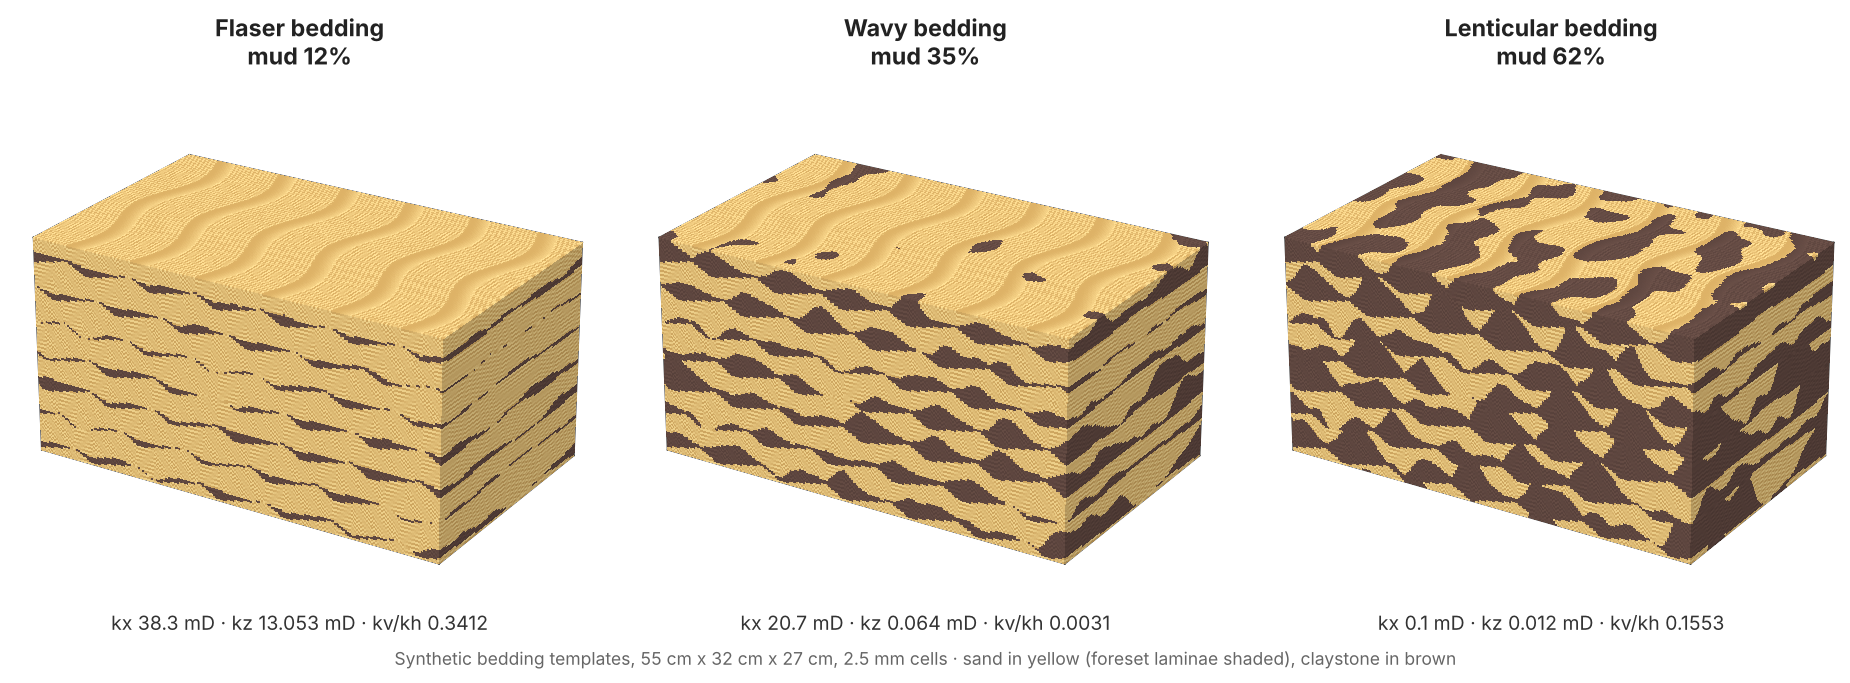

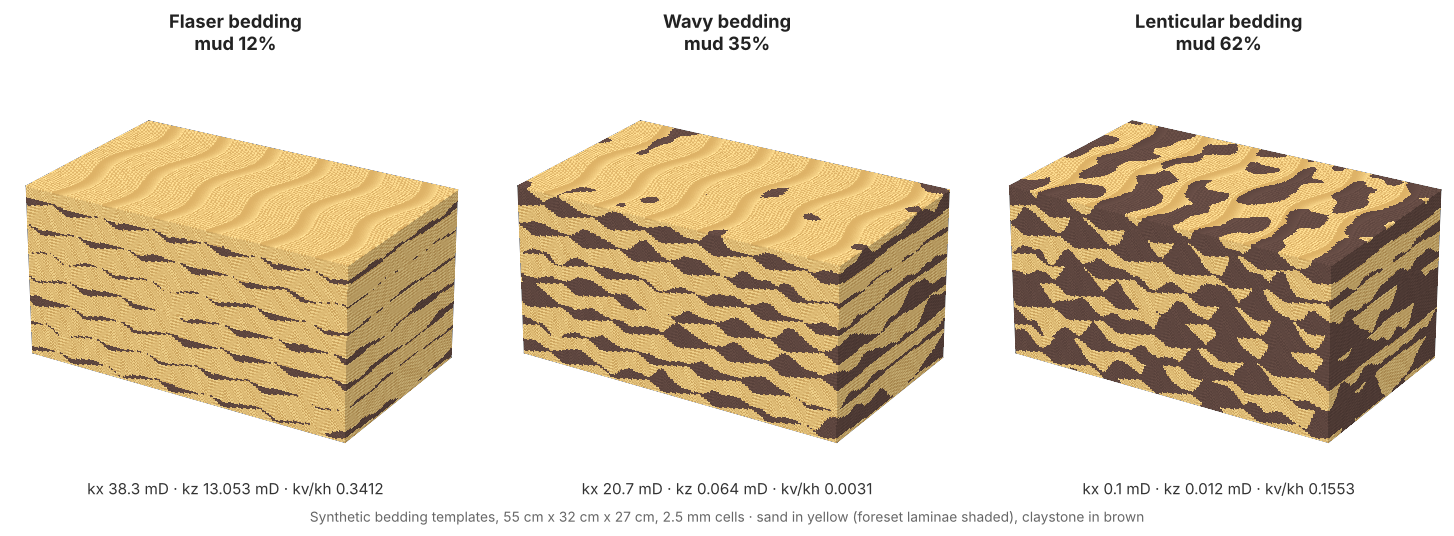

In [2]:
def block_k(mf, seed=0):
    mud, _ = kt.calibrated_bedding(200, 1, 200, mf, seed=seed)
    k = np.where(mud[:, 0, :], k_mud, k_sand); return kt.keff(k, "x"), kt.keff(k, "z")
labels = []
for mf in (0.12, 0.35, 0.62):
    kx, kz = block_k(mf); labels.append(f"kx {kx:.1f} mD · kz {kz:.3f} mD · kv/kh {kz/kx:.4f}")
kt.bedding_figure("figures/bedding_blocks.png", kvals=labels)
from IPython.display import Image; Image("figures/bedding_blocks.png")

In [3]:
mud_fractions = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]; sizes = np.unique(np.round(np.geomspace(8, 200, 14)).astype(int)); cell = 0.005; NR = 10
def lab_plugs(mud2d, n=8, count=20, seed=0):
    # vertical plugs (n cells, 4 cm) cut where a lab would: in the cleanest sandstone of a few candidate spots
    g = np.random.default_rng(seed); out = []
    for _ in range(count):
        best = None
        for _ in range(60):
            i, j = g.integers(0, mud2d.shape[1] - n), g.integers(0, mud2d.shape[0] - n); w = mud2d[j:j + n, i:i + n]
            if best is None or w.mean() < best.mean(): best = w
            if w.mean() <= 0.05: break
        out.append(kt.keff(np.where(best, k_mud, k_sand), "z"))
    return out
rows, plugk = [], {}
for mf in mud_fractions:
    for rlz in range(NR):
        mud, _ = kt.calibrated_bedding(200, 1, 200, mf, seed=100 * int(mf * 10) + rlz)
        rs = kt.rev_scan(np.where(mud[:, 0, :], k_mud, k_sand), sizes); rs["mud"] = mf; rs["rlz"] = rlz; rows.append(rs)
        plugk.setdefault(mf, []).extend(lab_plugs(mud[:, 0, :], seed=rlz))
R = pd.concat(rows); R["size_m"] = R.cells * cell
stats = R.groupby(["mud", "size_m"]).agg(kx=("kx", "mean"), kz=("kz", "mean"), cvx=("kx", lambda s: s.std() / s.mean()),
                                          cvz=("kz", lambda s: s.std() / s.mean())).reset_index()
def rev(cv, th):
    for i in range(len(cv)):
        if (cv.values[i:] < th).all(): return float(cv.index[i])
    return None
summary = []
for mf, g in stats.groupby("mud"):
    g = g.set_index("size_m"); plug = R[(R.mud == mf) & (R.cells == sizes[0])]; full = g.iloc[-1]
    summary.append({"mud fraction": mf, "kx 1 m (mD)": round(full.kx, 2), "kz 1 m (mD)": round(full.kz, 4), "kv/kh 1 m": round(full.kz / full.kx, 5),
                    "REV kx (m)": rev(g.cvx, 0.1), "REV kz (m)": rev(g.cvz, 0.5),
                    "random plug kz P90 / bed kz": round(float(plug.kz.quantile(.9) / full.kz), 1),
                    "lab plug kz median / bed kz": round(float(np.median(plugk[mf]) / full.kz), 1)})
summary = pd.DataFrame(summary); print(summary.to_string(index=False))

 mud fraction  kx 1 m (mD)  kz 1 m (mD)  kv/kh 1 m  REV kx (m)  REV kz (m)  random plug kz P90 / bed kz  lab plug kz median / bed kz
          0.1        39.32      18.0561    0.45925       0.040       0.085                          2.1                          2.2
          0.2        34.15       1.7641    0.05166       0.050       0.780                         13.1                         22.4
          0.3        27.24       0.1158    0.00425       0.225       0.610                         27.6                        321.3
          0.4        11.79       0.0329    0.00279         NaN       0.175                        351.9                        954.5
          0.5         1.31       0.0176    0.01344         NaN       0.040                          1.0                       1224.6
          0.6         0.11       0.0129    0.11442         NaN       0.085                          1.5                          3.1


## Permeability against sample size
Each line is one realisation of wavy bedding (35 % mud), measured in windows of growing size centred on the section. The dots are 4 cm plugs cut where a laboratory would cut them, in the cleanest sandstone: they sit two to three orders of magnitude above the bed-scale vertical permeability.

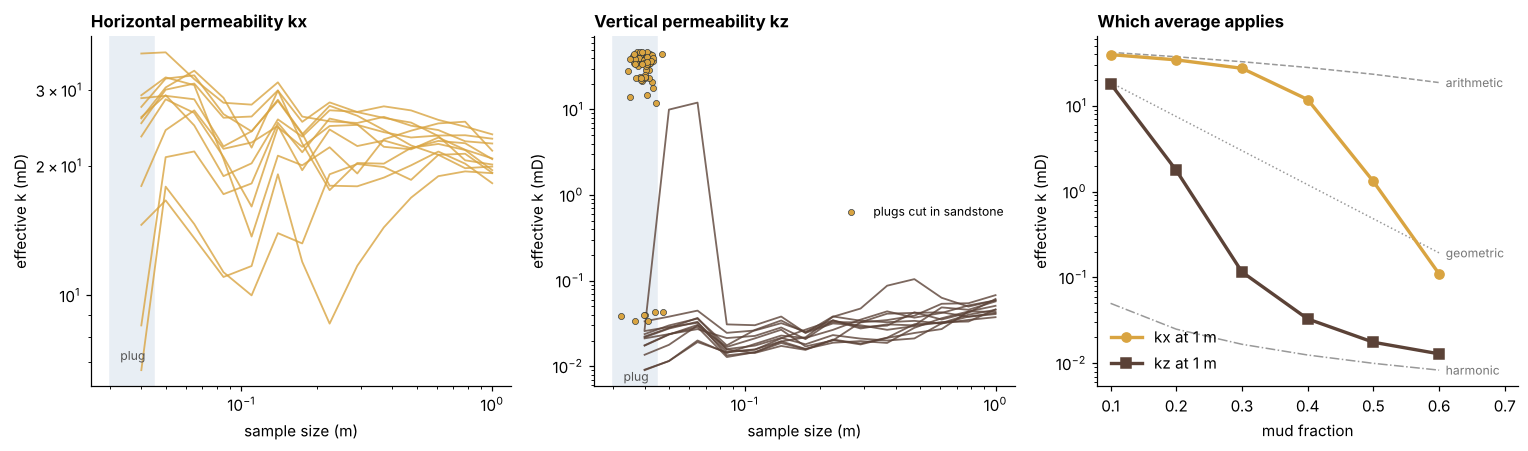

In [4]:
Wm = [kt.calibrated_bedding(200, 1, 200, 0.35, seed=500 + i)[0][:, 0, :] for i in range(12)]
W = pd.concat([kt.rev_scan(np.where(m2, k_mud, k_sand), sizes).assign(rlz=i) for i, m2 in enumerate(Wm)])
LP = np.concatenate([lab_plugs(m2, count=6, seed=i) for i, m2 in enumerate(Wm)])
W["size_m"] = W.cells * cell
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for i, g in W.groupby("rlz"):
    ax[0].loglog(g.size_m, g.kx, color=SAND, lw=1.2, alpha=.8); ax[1].loglog(g.size_m, g.kz, color=MUD, lw=1.2, alpha=.8)
ax[1].scatter(0.04 * np.exp(np.random.default_rng(1).normal(0, .08, len(LP))), LP, s=16, color=SAND, edgecolor=INK, lw=.4, zorder=5, label="plugs cut in sandstone")
ax[1].legend(loc="center right", fontsize=8, frameon=False)
for a_, t in zip(ax[:2], ["Horizontal permeability kx", "Vertical permeability kz"]):
    a_.axvspan(0.03, 0.045, color="#e8eef4"); a_.text(0.037, a_.get_ylim()[0] * 1.15, "plug", ha="center", fontsize=8, color="#555")
    a_.set_xlabel("sample size (m)"); a_.set_ylabel("effective k (mD)"); a_.set_title(t, loc="left")
m_ = np.array(mud_fractions); ari = (1 - m_) * k_sand + m_ * k_mud; har = 1 / ((1 - m_) / k_sand + m_ / k_mud); geo = k_sand ** (1 - m_) * k_mud ** m_
ax[2].semilogy(m_, ari, color="#999", lw=1, ls="--"); ax[2].semilogy(m_, geo, color="#999", lw=1, ls=":"); ax[2].semilogy(m_, har, color="#999", lw=1, ls="-.")
ax[2].semilogy(m_, summary["kx 1 m (mD)"], "o-", color=SAND, lw=2.2, ms=6, label="kx at 1 m"); ax[2].semilogy(m_, summary["kz 1 m (mD)"], "s-", color=MUD, lw=2.2, ms=6, label="kz at 1 m")
for y, t in [(ari[-1], "arithmetic"), (geo[-1], "geometric"), (har[-1], "harmonic")]: ax[2].text(m_[-1] + .01, y, t, fontsize=8, color="#777", va="center")
ax[2].set_xlim(.08, .72); ax[2].set_xlabel("mud fraction"); ax[2].set_ylabel("effective k (mD)"); ax[2].set_title("Which average applies", loc="left"); ax[2].legend(loc="lower left")
fig.tight_layout(); fig.savefig("figures/rev_upscaling.png", dpi=150)

In [5]:
summary.to_csv("results/rev_summary.csv", index=False)
json.dump({"k_sand_mD": round(k_sand, 2), "k_mud_mD": k_mud, "cell_m": cell, "realisations": NR, "template": "ripple-laminated (flaser-wavy-lenticular)",
           "summary": summary.to_dict("records")}, open("results/nb3_rev.json", "w"), indent=1, default=float)
mid = summary[summary["mud fraction"].between(0.2, 0.4)]
assert mid["kv/kh 1 m"].max() < 0.2 and mid["lab plug kz median / bed kz"].min() > 10

## Result and limits
* Horizontal permeability settles within decimetres in sand-rich bedding and stays close to the arithmetic average; it needs longer windows as mud increases.
* Vertical permeability is the problem. A plug cut where a laboratory cuts it, in competent sandstone, overstates bed-scale kz by one to three orders of magnitude in wavy bedding (column `lab plug kz median / bed kz`); random plugs scatter both ways (`random plug kz P90 / bed kz`), and bed-scale kv/kh falls far below the plug value of about 1 (notebook 1). kz moves from the geometric towards the harmonic average as mud increases: the flow upscaling regimes of Ringrose et al. (2003).
* Limits: 2D sections for the flow, one ripple geometry, two components. Real templates come from the core description of each facies; the workflow, not these exact numbers, is what transfers to a client's core.

*References:* Nordahl, K. and Ringrose, P.S. (2008) Math. Geosci. 40, 753-771 · Ringrose, P.S. et al. (2003) Petroleum Geoscience 9, 13-23.